# Earthquake Building Damage — Data Preprocessing & Analysis

**Course project:** Data Preprocessing & Analysis

This notebook follows the project brief: audit raw data, document cleaning decisions, prepare features, perform EDA, and export clean files. **No machine learning or train/test split is used.**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize':(9,5)})

## 1. Load and understand the raw data

In [2]:
values = pd.read_csv('../data/raw/train_values.csv')
labels = pd.read_csv('../data/raw/train_labels.csv')
df = values.merge(labels, on='building_id', how='inner', validate='one_to_one')
print('Values:', values.shape)
print('Labels:', labels.shape)
print('Merged:', df.shape)
display(df.head())

Values: (260601, 39)
Labels: (260601, 2)
Merged: (260601, 40)


,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
0,802906,6,487,12198,2,30,6,5,t,r,n,f,q,t,d,1,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
1,28830,8,900,2812,2,10,8,7,o,r,n,x,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
2,94947,21,363,8973,2,10,5,5,t,r,n,f,x,t,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
3,590882,22,418,10694,2,10,6,5,t,r,n,f,x,s,d,0,1,0,0,0,0,1,1,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
4,201944,11,131,1488,3,30,8,9,t,r,n,f,x,s,d,1,0,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3


In [3]:
print('One row represents one building.')
print('Missing values:', int(df.isna().sum().sum()))
print('Duplicate rows:', int(df.duplicated().sum()))
print('Duplicate building IDs:', int(df.building_id.duplicated().sum()))

One row represents one building.
Missing values: 0


Duplicate rows: 0
Duplicate building IDs: 0


## 2. Data quality audit

In [4]:
display(pd.DataFrame({'dtype':df.dtypes.astype(str),'missing':df.isna().sum(),'unique':df.nunique()}))

,dtype,missing,unique
building_id,int64,0,260601
geo_level_1_id,int64,0,31
geo_level_2_id,int64,0,1414
geo_level_3_id,int64,0,11595
count_floors_pre_eq,int64,0,9
age,int64,0,42
area_percentage,int64,0,84
height_percentage,int64,0,27
land_surface_condition,object,0,3
foundation_type,object,0,5


In [5]:
categorical = df.select_dtypes('object').columns.tolist()
print('Categorical columns:', categorical)
for c in categorical:
    print('\n',c)
    display(df[c].value_counts().to_frame('count'))

Categorical columns: ['land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'legal_ownership_status']

 land_surface_condition


,count
land_surface_condition,
t,216757
n,35528
o,8316



 foundation_type


,count
foundation_type,
r,219196
w,15118
u,14260
i,10579
h,1448



 roof_type


,count
roof_type,
n,182842
q,61576
x,16183


... (6 outputs left out)


 plan_configuration


,count
plan_configuration,
d,250072
q,5692
u,3649
s,346
c,325
a,252
o,159
m,46
n,38



 legal_ownership_status


,count
legal_ownership_status,
v,250939
a,5512
w,2677
r,1473


### Outlier investigation — age

In [6]:
q1,q3 = df['age'].quantile([.25,.75]); iqr=q3-q1; upper=q3+1.5*iqr
print(f'Q1={q1:.1f}, Q3={q3:.1f}, IQR={iqr:.1f}, upper IQR bound={upper:.1f}')
print('Age = 995:', int((df.age==995).sum()))
print('Age > 100:', int((df.age>100).sum()))

Q1=10.0, Q3=30.0, IQR=20.0, upper IQR bound=60.0
Age = 995: 1390
Age > 100: 2124


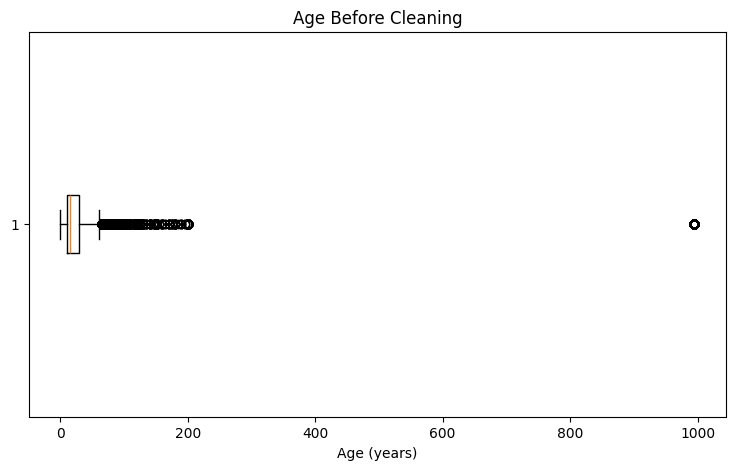

In [7]:
fig,ax=plt.subplots()
ax.boxplot(df['age'],vert=False)
ax.set_title('Age Before Cleaning')
ax.set_xlabel('Age (years)')
plt.show()

## 3. Cleaning decisions

- Missing values: none found, so no imputation was required.
- Duplicate rows/IDs: none found, so no deletion was required.
- Categories: values are internally consistent and no unknown category is present.
- Age = 995: treated as an extreme data-quality value. To avoid deleting 1,390 otherwise usable building records, it is replaced with the median age calculated after excluding 995. The correction is explicitly flagged.

In [8]:
clean=df.copy()
median_age = int(clean.loc[clean.age != 995, 'age'].median())
clean['age_original'] = clean['age']
clean['age_was_corrected'] = (clean['age']==995).astype(int)
clean.loc[clean['age']==995,'age'] = median_age
print('Median age used:',median_age)
print('Corrected rows:',int(clean.age_was_corrected.sum()))

Median age used: 15
Corrected rows: 1390


## 4. Feature engineering and preparation

In [9]:
super_cols=[c for c in clean.columns if c.startswith('has_superstructure_')]
secondary_cols=[c for c in clean.columns if c.startswith('has_secondary_use')]
clean['superstructure_count']=clean[super_cols].sum(axis=1)
clean['secondary_use_count']=clean[secondary_cols].sum(axis=1)
clean['height_per_floor']=clean['height_percentage']/clean['count_floors_pre_eq']
clean['age_group']=pd.cut(clean['age'],bins=[-1,10,20,40,80,10**6],labels=['0-10','11-20','21-40','41-80','81+']).astype(str)
print('Added: superstructure_count, secondary_use_count, height_per_floor, age_group')

Added: superstructure_count, secondary_use_count, height_per_floor, age_group


### Encoding

In [10]:
categorical = clean.select_dtypes('object').columns.tolist()
encoded = pd.get_dummies(clean.drop(columns=['age_original']), columns=categorical, drop_first=False, dtype=int)
print('Before encoding:', clean.drop(columns=['age_original']).shape)
print('After encoding:', encoded.shape)

Before encoding: (260601, 45)
After encoding: (260601, 79)


### Scaling

In [11]:
scale_cols=['age','area_percentage','height_percentage','count_floors_pre_eq','count_families','height_per_floor','superstructure_count','secondary_use_count']
for c in scale_cols:
    mu=encoded[c].mean(); sd=encoded[c].std(ddof=0)
    encoded[c+'_zscore']=(encoded[c]-mu)/sd if sd else 0
print('Created z-score versions of selected continuous features.')

Created z-score versions of selected continuous features.


## 5. EDA

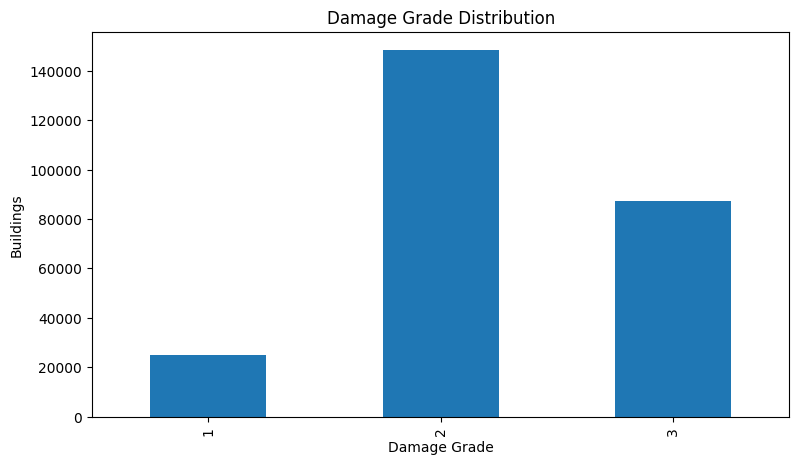

In [12]:
fig,ax=plt.subplots(); df.damage_grade.value_counts().sort_index().plot(kind='bar',ax=ax); ax.set_title('Damage Grade Distribution'); ax.set_xlabel('Damage Grade'); ax.set_ylabel('Buildings'); plt.show()

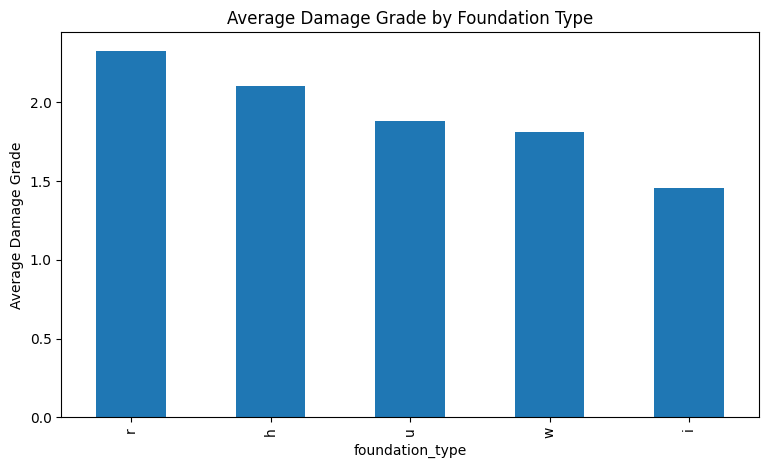

In [13]:
fig,ax=plt.subplots(); df.groupby('foundation_type').damage_grade.mean().sort_values(ascending=False).plot(kind='bar',ax=ax); ax.set_title('Average Damage Grade by Foundation Type'); ax.set_ylabel('Average Damage Grade'); plt.show()

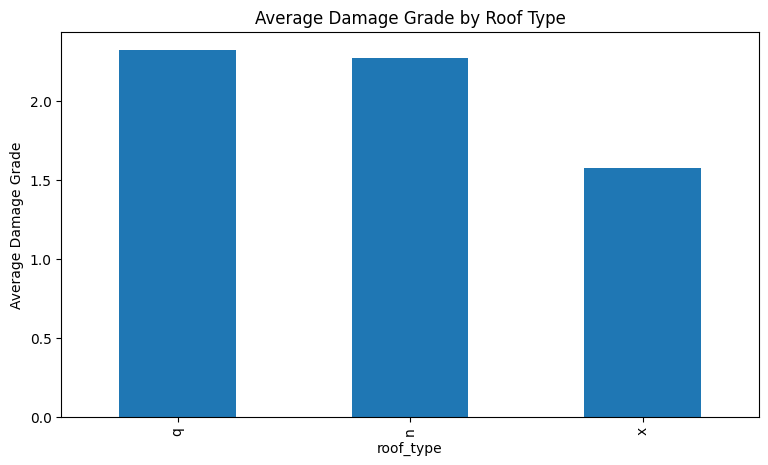

In [14]:
fig,ax=plt.subplots(); df.groupby('roof_type').damage_grade.mean().sort_values(ascending=False).plot(kind='bar',ax=ax); ax.set_title('Average Damage Grade by Roof Type'); ax.set_ylabel('Average Damage Grade'); plt.show()

In [15]:
corr=df.select_dtypes(exclude='object').corr()['damage_grade'].drop('damage_grade').sort_values()
display(corr.to_frame('correlation').head(8)); display(corr.to_frame('correlation').tail(8))

,correlation
has_superstructure_cement_mortar_brick,-0.254131
has_superstructure_rc_engineered,-0.179014
has_superstructure_rc_non_engineered,-0.158145
area_percentage,-0.125221
has_secondary_use_hotel,-0.097942
has_secondary_use_rental,-0.083754
has_secondary_use,-0.079630
geo_level_1_id,-0.072347


,correlation
age,0.029273
geo_level_2_id,0.043161
height_percentage,0.048130
has_superstructure_adobe_mud,0.055314
count_families,0.056151
has_superstructure_stone_flag,0.066039
count_floors_pre_eq,0.122308
has_superstructure_mud_mortar_stone,0.291325


## 6. Before vs After and export

In [16]:
print('Before:',df.shape)
print('After processed:',encoded.shape)
print('Processed missing:',int(encoded.isna().sum().sum()))
print('Processed duplicates:',int(encoded.duplicated().sum()))

Before: (260601, 40)
After processed: (260601, 87)
Processed missing: 0
Processed duplicates: 0


In [17]:
encoded.to_csv('../data/processed/earthquake_damage_processed.csv',index=False)
clean.drop(columns=['age_original']).to_csv('../data/processed/earthquake_damage_powerbi.csv',index=False)
print('Exported processed datasets.')

Exported processed datasets.
